# Lecture 9: Classifying Handwritten Digits
In this lecture we will introduce a classic problem in machine learning---classification of handwritten digits. In particular we will:
- Introduce and visualize the data sets.
- Discuss several elementary algorithms. 
- Discuss using the SVD for this problem.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.neighbors import KDTree
import heapq

In [3]:
# load the data set. Note that sklearn comes with several standard  small data sets built in.
# The handwritten digits data set we'll use is different to the one used in the textbook.
dataset = datasets.load_digits()
digits = dataset.data
Number_of_Images = digits.shape[0]
labels = dataset.target
print(digits.shape)
print(labels[0:50])

(1797, 64)
[0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9 0 9 5 5 6 5 0
 9 8 9 8 4 1 7 7 3 5 1 0 0]


The images in this data set are 8-by-8 greyscale, and there are 1797 of them. Note that the images are vectorized into 64 dimensional vectors. We can undo this use the np.reshape command in the next code block

[[ 0.  1. 12. 16. 16.  9.  0.  0.]
 [ 0. 11. 15.  9.  7. 16.  3.  0.]
 [ 0. 13.  3.  1. 10. 15.  1.  0.]
 [ 0.  0.  0. 11. 16.  8.  0.  0.]
 [ 0.  0.  0.  5. 15. 16.  5.  0.]
 [ 0.  0.  0.  0.  0. 10. 13.  0.]
 [ 0.  0.  7.  4.  8. 15.  9.  0.]
 [ 0.  0. 13. 16. 16. 12.  1.  0.]]


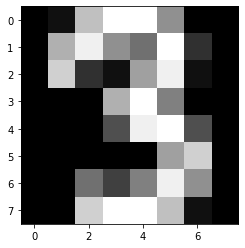

In [4]:
## Lets visualize some digits
Sample_digit = np.reshape(digits[np.random.randint(low = 0, high = Number_of_Images-1),:],[8,8])
print(Sample_digit)
im = plt.imshow(Sample_digit, cmap = 'gray')

In [5]:
## Now we'll split the data into test and train sets.
n_train = 1500;
n_test = Number_of_Images - n_train;
Training_digits = digits[0:n_train,:]
Training_labels = labels[0:n_train]
Testing_digits = digits[n_test:Number_of_Images,:]
Testing_labels = labels[n_test:Number_of_Images]

### Splitting Datasets in ML
Why did we divide our data set like this? Common practice when tackling classification problems is to use ~ 90% of your data to develop or train your data, and keeping ~ 10% back to test the accuracy of this algorithm. That way, we can get some feel for how the algorithm will work when deployed and used to classify unseen data.

In what follows we will denote the images in the training set as $I_{1},I_{2}, \ldots, I_{n_{train}}$ and their corresponding labels as $y_1,y_2,\ldots, y_{n_{train}}$

## Attempt 1: k-nearest neighbors
This is arguably the simplest possible classification algorithm. It requires no training and has only two steps:

- **Input** An image $\tilde{I}$ to be classified
    1. Find the $k$ images $I_{i_1},\ldots, I_{i_k}$ in the Training set closest to $\tilde{I}$.
    2. Let $\tilde{y}$ be the most common label amongst $y_{i_1},\ldots, y_{i_k}$.
- **Output** the assigned label $\tilde{y}$.

Note that $k$ is a (hyper-) parameter to be manually set by the user. Lets implement this algorithm!

In [6]:
def NNClassifier(I_tilde,k = 25):
    Distance_Vector = np.sqrt(np.sum((Training_digits - I_tilde)**2,axis = 1))
    Sorted_Inds = np.argsort(Distance_Vector) #CAUTION: This is not the fastest way to do this.
    K_nearest_neighbors = Sorted_Inds[0:k]
    Labels_of_K_nearest_neighbors = np.ndarray.tolist(Training_labels[K_nearest_neighbors]) # it makes life a lil easier to convert this to a list
    # print(Labels_of_K_nearest_neighbors)
    # the next few lines compute the number of k nearest neighbors that have each label
    Label_Count = np.zeros([10,1])
    for a in range(0,10):
        Label_Count[a] = Labels_of_K_nearest_neighbors.count(a)
    y_tilde = np.argmax(Label_Count)
    return y_tilde
    
    

In [9]:
y_tilde = NNClassifier(Testing_digits[37,:])
print(y_tilde)
print(Testing_labels[37])

0
0


Experiment with the above algorithm! Also, try uncomment the line print(Labels_of_K_nearest_neighbors) so that you can see the labels of the k-nearest neighbors. You might also consider changing the value of k. In the next cell we'll calculate the accuracy of this algorithm.

In [10]:
## Computing accuracy of the K_nearest_neighbors algorithm
Agreement_vector = np.zeros([n_test,1])
# We'll fill this agreement vector with a 1 in the i-th position if the label for test image I_{i} predicted 
# by NNClassifier is correct.
for i in range(0,n_test):
    y_tilde = NNClassifier(Testing_digits[i,:])
    if y_tilde == Testing_labels[i]:
        Agreement_vector[i] = 1
        
Accuracy = 100*np.sum(Agreement_vector)/n_test
print('NNClassifier has an accuracy of ' + str(Accuracy) + '%')
        

NNClassifier has an accuracy of 97.3063973063973%


### Discussion of the k-NN classifier
**Pros**
- Easy!
- Gives good performance on simple data sets.

**Cons**
- Don't expect such high accuracy on more complicated data sets
- Memory
- Run time

**Possible Modification** 
- Divide Training data into $k$ clusters, $\mathcal{X}_1\cup \mathcal{X}_{k}$ and compute the means/centroids $\mu_1,\ldots, \mu_k$
- Only store $\mu_1,\ldots, \mu_k$
- At test time, for unknown image $\tilde{I}$ only compute $\|\tilde{I} - \mu_{i}\|_{2}$ for $i=1,\ldots, k$. 
- Assign $\tilde{I}$ to whichever cluster's centroid is closest to $\tilde{I}$

## Attempt 2: Using SVD bases
**Idea:**
- All images of same digit (*e.g.* 2) are similar, so lets suppose they live in a low dimensional subspace, call it $\mathcal{U}^{(2)}\subset\mathbb{R}^{64}$
- **Question** Why low dimensional?
- For an unlabeled digit $\tilde{I}$ check which subspace it is closest to.
- Assign $\tilde{I}$ the label $\tilde{y}$ corresponding to the subspace it is closest too.

**Questions:**
- How to find the subspaces $\mathcal{U}^{(a)}$?
- How to compute the distance between $\tilde{I}$ and $\mathcal{U}^{(a)}$?

### Finding the subspaces
- Stack all the vectorizes images of the same digit into a matrix:
\begin{align}
    A^{(a)} = \left[I^{(a)}_{1},\ldots, I^{(a)}_{n_a}\right] \quad \text{ where the } I^{(a)}_{i} \text{ all have labels } y_{i_{\ell}} = a 
\end{align}
- Take SVD: $A^{(a)} = U^{(a)}\Sigma \left(V^{(a)}\right)^{\top}$
- Let $\mathbf{u}^{(a)}_1,\ldots, \mathbf{u}^{(a)}_{64}$ denote the left singular vectors/ columns of $U^{(a)}$.
- **Claim** $\mathbf{u}^{(a)}_1,\ldots, \mathbf{u}^{(a)}_{64}$ form a basis for the column space of $A^{(a)}$. That is, every image in this class can be expressed as a linear combination of the $\mathbf{u}^{(a)}_1,\ldots, \mathbf{u}^{(a)}_{64}$:
\begin{align}
I_{j}^{(a)} = \sum_{i=1}^{64}(\sigma^{(a)}_i v^{(a)}_{ji})\mathbf{u}^{(a)}_{i} \approx \sum_{i=1}^{r}(\sigma^{(a)}_i v^{(a)}_{ji})\mathbf{u}^{(a)}_{i}
\end{align}

For some $r\ll 64$ as the singular values $\sigma^{(a)}_{i}$ are *decaying*.
- Take $\mathcal{V}^{(a)} = \text{span}\left\{\mathbf{u}_{1}^{(a)},\ldots,\mathbf{u}_{r}^{(a)} \right\}$ 

### Finding which subspace is closest to $\tilde{I}$
- **Definition:** $\displaystyle \text{dist}(\tilde{I},\mathcal{V}^{(a)}) = \min_{\mathbf{x}\in\mathcal{V}^{(a)}}\|\tilde{I} - \mathbf{x}\|_{2}$
- Computing this would appear to require checking an infinite number of vectors, but actually there is a simple solution:
    - $If \displaystyle \mathbf{x}^{*} := \text{argmin}_{\mathbf{x}\in\mathcal{V}^{(a)}}\|\tilde{I} - \mathbf{x}\|_{2}$ then $\displaystyle \mathbf{x}^{*} = \sum_{i=1}^{r}\left(\left(\mathbf{u}_{i}^{(a)}\right)^{\top}\tilde{I}\right)\mathbf{u}_{i} = U_{r}^{(a)}\left(U_{r}^{(a)}\right)^{\top}\tilde{I}$ 
    - So: $\displaystyle \min_{\mathbf{x}\in\mathcal{V}^{(a)}}\|\tilde{I} - \mathbf{x}\|_{2} = \|\tilde{I} - \mathbf{x}^{*}\| = \left| \tilde{I} - U_{r}^{(a)}\left(U^{(a)}\right)^{\top}\tilde{I}\right\| = \left\|\left[I_{64\times 64} - U_{r}^{(a)}\left(U_{r}^{(a)}\right)^{\top}\right]\tilde{I}\right\|$ *(Here $I_{[64\times 64}$ denotes the 64-by-64 identity matrix. Apologies for the notational conflict!)*
    - So, define $\Pi^{(a)} = I_{64\times 64} - U_{r}^{(a)}\left(U_{r}^{(a)}\right)^{\top}$ *(the projection matrix on to $\mathcal{V}^{(a)}$)* then:
    \begin{align}
        \text{dist}(\tilde{I},\mathcal{V}^{(a)}) = \|\Pi^{(a)}\tilde{I}\|_{2}
    \end{align}
    

### the SVD-Projection Classifier
- **Training**
    1. Sort training data. Combine vectorized images of digit a into $A^{(a)}\in\mathbb{R}^{64\times n_{a}}$ 
    2. for $a = 1,\ldots, k$:
        1. Compute the SVD $A^{(a)} = U^{(a)}\Sigma^{(a)}\left(V^{(a)}\right)^{\top}$ 
        2. Retain the first $r$ columns of $U^{(a)}$ to make $U^{(a)}_{r}$
        3. Construct $\Pi^{(a)} = I_{64\times 64} - U_{r}^{(a)}\left(U_{r}^{(a)}\right)^{\top}$, discard everything else
        
- **Classification**
    - **Input** An image $\tilde{I}$ to be classified.
    - Let $\displaystyle \tilde{y} = \text{argmin}_{a}\left\|\Pi^{(a)}\tilde{I}\right\|_2$ 
    - **Output** Predicted label $\tilde{y}$
    
Lets implement this algorithm:

In [82]:
## Training the SVD-Projection classifier
print(Training_digits.shape)
r = 15  # dimension of the low dim subspaces.
Pi = np.zeros([64,64,10])  #We will store each Pi^{(a)} as a slice of a tensor.
for a in range(0,10):
    Indices = Training_labels == a
    A = Training_digits[Indices,:].T
    U,_,_ = np.linalg.svd(A)
    U_r = U[:,0:r]
    Pi[:,:,a] = np.identity(64) - np.dot(U_r,U_r.T)

(1500, 64)


In [94]:
## Define the classifier
def SVD_Classifier(I_tilde):
    Distance_Vector = np.zeros([10,1])
    for a in range(0,10):
        Pi_a = np.ndarray.squeeze(Pi[:,:,a])
        Distance_Vector[a] = np.linalg.norm(np.dot(Pi_a,I_tilde))
    y_tilde = np.argmin(Distance_Vector)
    return y_tilde

In [100]:
## Test this classifier
random_index = np.random.randint(low = 0,high = n_test)
y_tilde = SVD_Classifier(Testing_digits[random_index,:].T)
print(y_tilde)
print(Testing_labels[random_index])

2
2


In [99]:
## Computing accuracy of the SVD_Classifier
Agreement_vector = np.zeros([n_test,1])
# We'll fill this agreement vector with a 1 in the i-th position if the label for test image I_{i} predicted 
# by SVD_Classifier is correct.
for i in range(0,n_test):
    y_tilde = SVD_Classifier(Testing_digits[i,:])
    if y_tilde == Testing_labels[i]:
        Agreement_vector[i] = 1
        
Accuracy = 100*np.sum(Agreement_vector)/n_test
print('SVD_Classifier has an accuracy of ' + str(Accuracy) + '%')
        

SVD_Classifier has an accuracy of 100.0%


### Discussion

- Compare with HOSVD
- Again, don't expect this to work this well on more complicated data sets.
- State of the art methods?